In [5]:
# 1. Write a program to enhance the contrast of the input grayscale image
# using histogram equalization. Display the original image and equalized
# image. 

In [6]:
pip install opencv-python matplotlib

Defaulting to user installation because normal site-packages is not writeable
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.5 MB 4.1 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/9.5 MB 3.1 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.5 MB 3.3 MB/s eta 0:00:03
   ------------- -------------------------- 3.1/9.5 MB 3.8 MB/s eta 0:00:02
   ----------------- ---------------------- 4.2/9.5 MB 3.9 MB/s eta 0:00:02
   -------------------- ------------------- 5.0/9.5 MB 4.0 MB/s eta 0:00:02
   ---------------------------- ----------- 6.8/9.5 MB 4.6 MB/s eta 0:00:01
   ---------------------------------- ----- 8.1/9.5 MB 4.9 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.5 MB 5.0 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 4.9 MB/s  0:00:01
Using cached cycler-0.12.1-py3-n


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


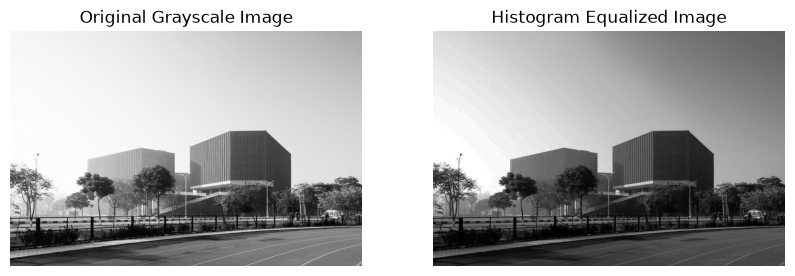

In [7]:

import cv2
import matplotlib.pyplot as plt

# Read the input grayscale image
img = cv2.imread('image.jpg', 0)

# Apply Histogram Equalization
equalized_img = cv2.equalizeHist(img)

# Display original and equalized images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(equalized_img, cmap='gray')
plt.title('Histogram Equalized Image')
plt.axis('off')

plt.show()


In [ ]:
# 2. Write a program to perform histogram matching of the input image with
# that of reference image using histogram equalization

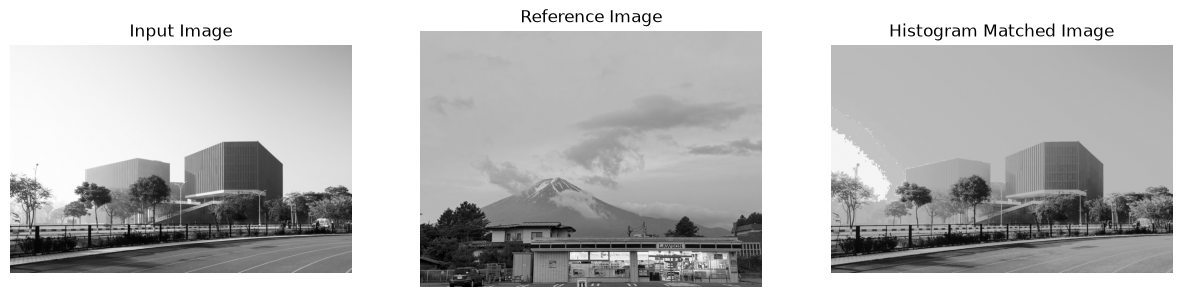

In [8]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read input and reference images in grayscale
input_img = cv2.imread('input.jpg', 0)
ref_img = cv2.imread('reference.jpeg', 0)

# Calculate histograms
input_hist = cv2.calcHist([input_img], [0], None, [256], [0, 256])
ref_hist = cv2.calcHist([ref_img], [0], None, [256], [0, 256])

# Calculate cumulative distribution functions (CDF)
input_cdf = input_hist.cumsum()
ref_cdf = ref_hist.cumsum()

# Normalize CDF
input_cdf = input_cdf / input_cdf[-1]
ref_cdf = ref_cdf / ref_cdf[-1]

# Create mapping between input and reference intensities
mapping = np.zeros(256, dtype=np.uint8)

for i in range(256):
    mapping[i] = np.argmin(np.abs(ref_cdf - input_cdf[i]))

# Apply histogram matching
matched_img = mapping[input_img]

# Display images
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(input_img, cmap='gray')
plt.title('Input Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(ref_img, cmap='gray')
plt.title('Reference Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(matched_img, cmap='gray')
plt.title('Histogram Matched Image')
plt.axis('off')

plt.show()
